<a href="https://colab.research.google.com/github/Brown-Sam-1/data_science/blob/main/Masters_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# This command allows you to run `pip install <package>` within a Jupyter Notebook
import sys
!{sys.executable} -m pip install --quiet "gwosc" "gwpy" "matplotlib" "pycbc" "ligo.skymap" "pesummary>=0.13.2" "pepredicates" "p_astro"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import matplotlib.pyplot as plt
import pesummary
from pesummary.io import read
import h5py
import numpy as np
%matplotlib inline
%config InlineBackend.figure_format='retina'
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal
from lal import LIGOTimeGPS

In [4]:
from gwpy.table import EventTable

In [5]:
#!curl "https://zenodo.org/records/20348006/files/IGWN-GWTC5p0-29ebe06b7_25-GW250114_082203-combined_PEDataRelease.hdf5?download=1" -o /content/IGWN-GWTC5p0-29ebe06b7_25-GW250114_082203-combined_PEDataRelease.hdf5
!curl "https://zenodo.org/records/20276106/files/IGWN-GWTC5p0-59d160a18_25-GW240507_041632-combined_PEDataRelease.hdf5?download=1" -o /content/IGWN-GWTC5p0-59d160a18_25-GW240507_041632-combined_PEDataRelease.hdf5

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  416M  100  416M    0     0  16.0M      0  0:00:26  0:00:26 --:--:-- 14.0M


In [6]:
#GW250114 = read("/content/IGWN-GWTC5p0-29ebe06b7_25-GW250114_082203-combined_PEDataRelease.hdf5")
GW240507 = read("/content/IGWN-GWTC5p0-59d160a18_25-GW240507_041632-combined_PEDataRelease.hdf5")

In [7]:
samples_dict = GW240507.samples_dict
posterior_samples = samples_dict["C00:IMRPhenomXPHM-SpinTaylor"]

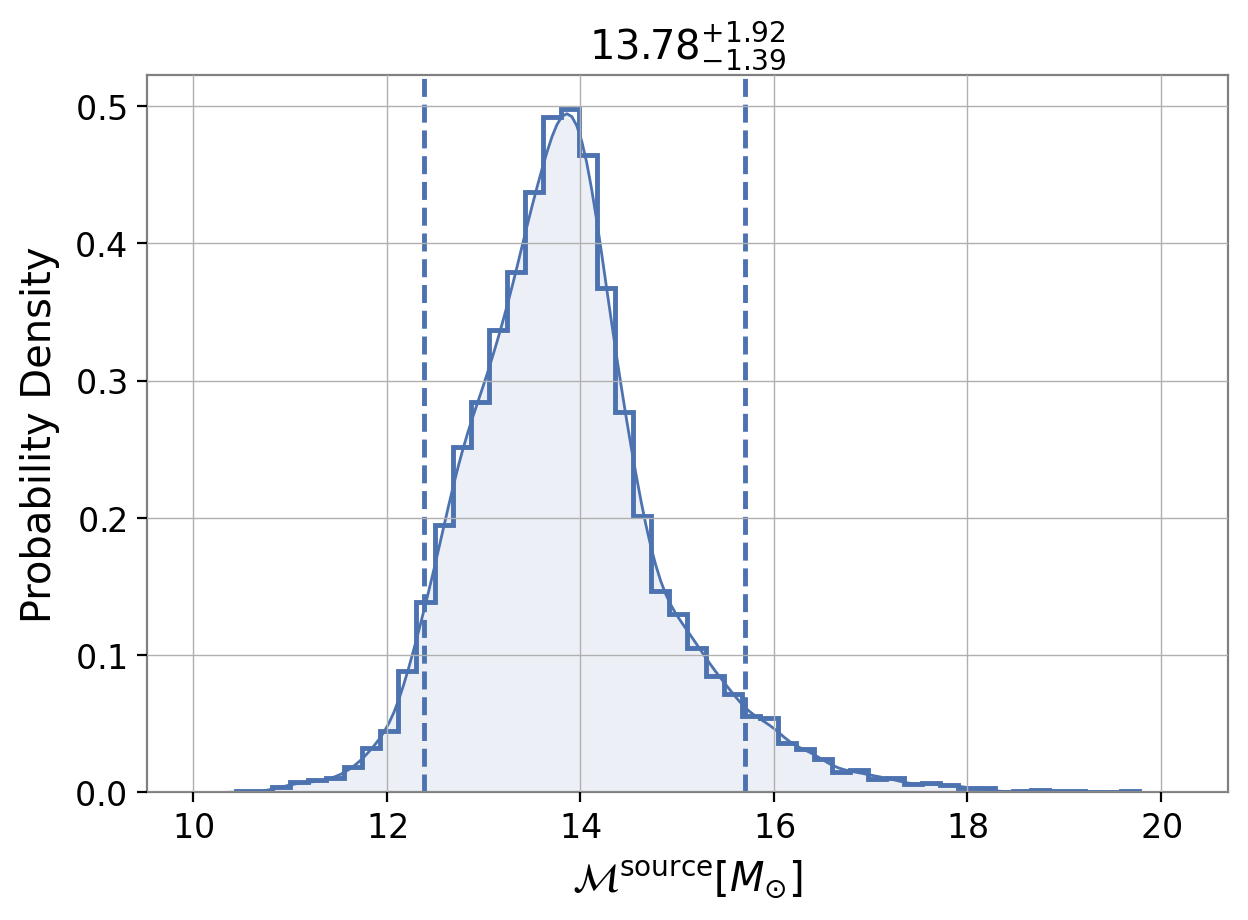

In [8]:
fig = posterior_samples.plot("chirp_mass_source", type="hist", kde=True)

In [9]:
parameters = posterior_samples.parameters
print(parameters[:10])

['H1_log_likelihood', 'H1_matched_filter_snr', 'H1_optimal_snr', 'L1_log_likelihood', 'L1_matched_filter_snr', 'L1_optimal_snr', 'L1_time', 'V1_log_likelihood', 'V1_matched_filter_snr', 'V1_optimal_snr']


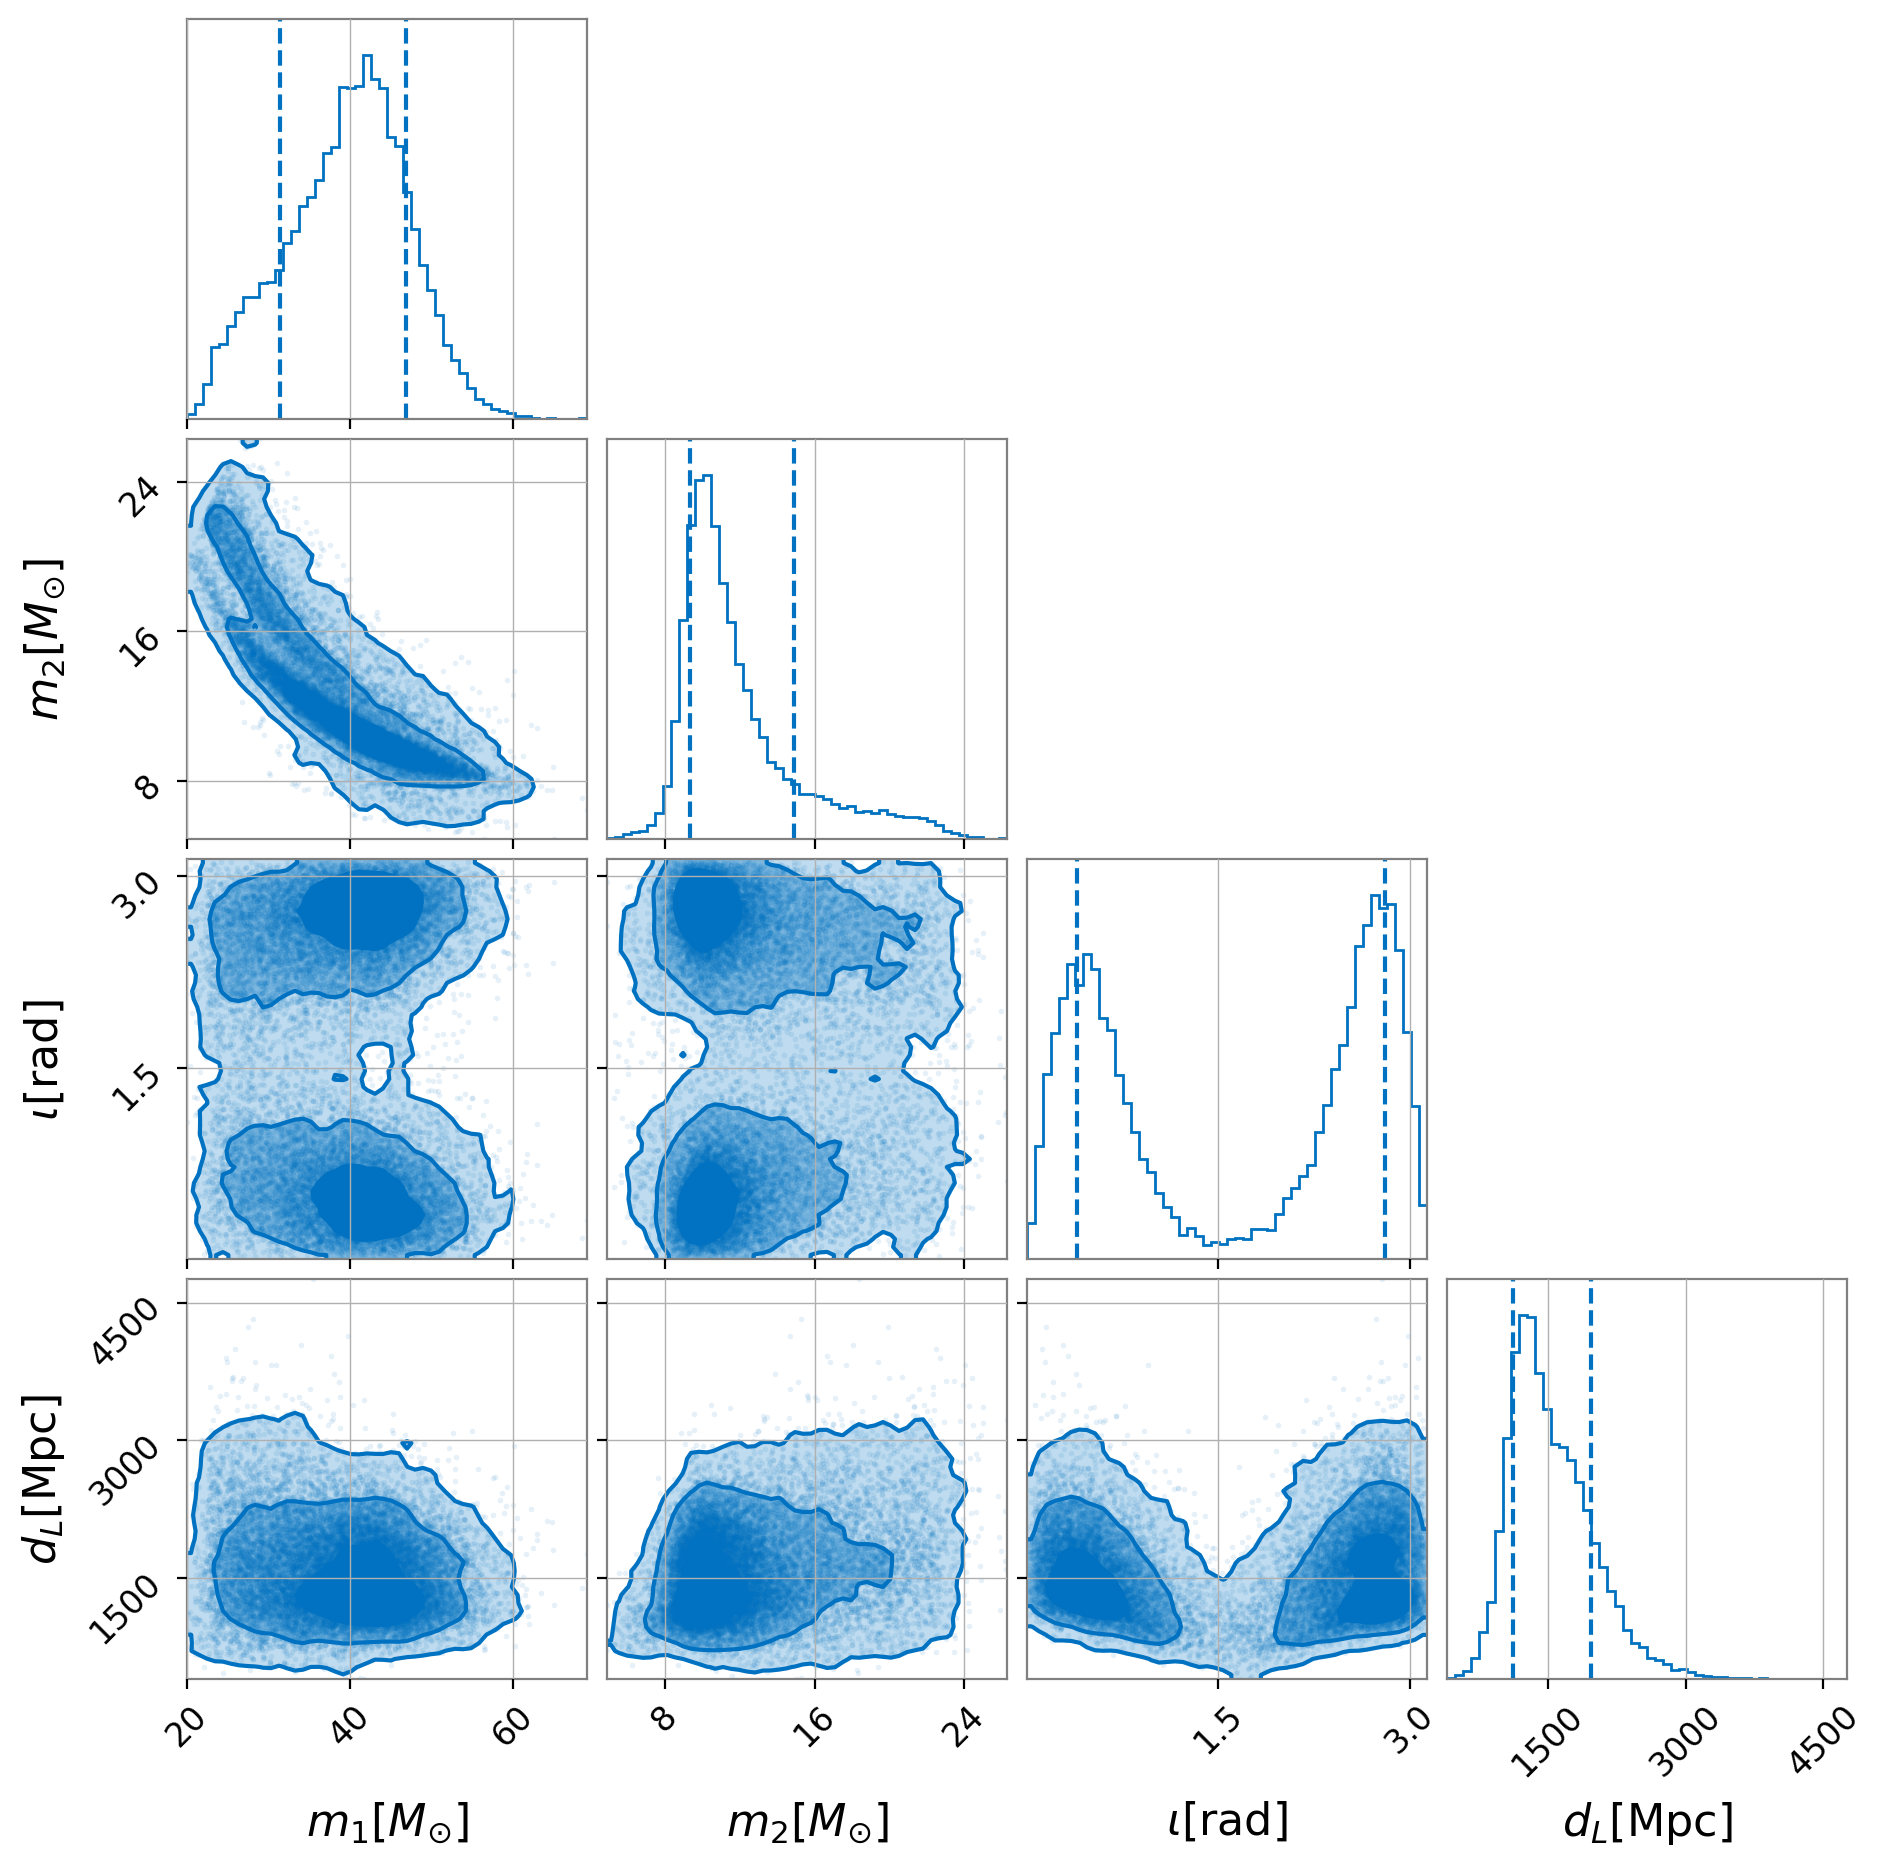

In [10]:
fig = posterior_samples.plot(type="corner",
                             parameters=["mass_1",
                                         "mass_2",
                                         "iota",
                                         "luminosity_distance"])

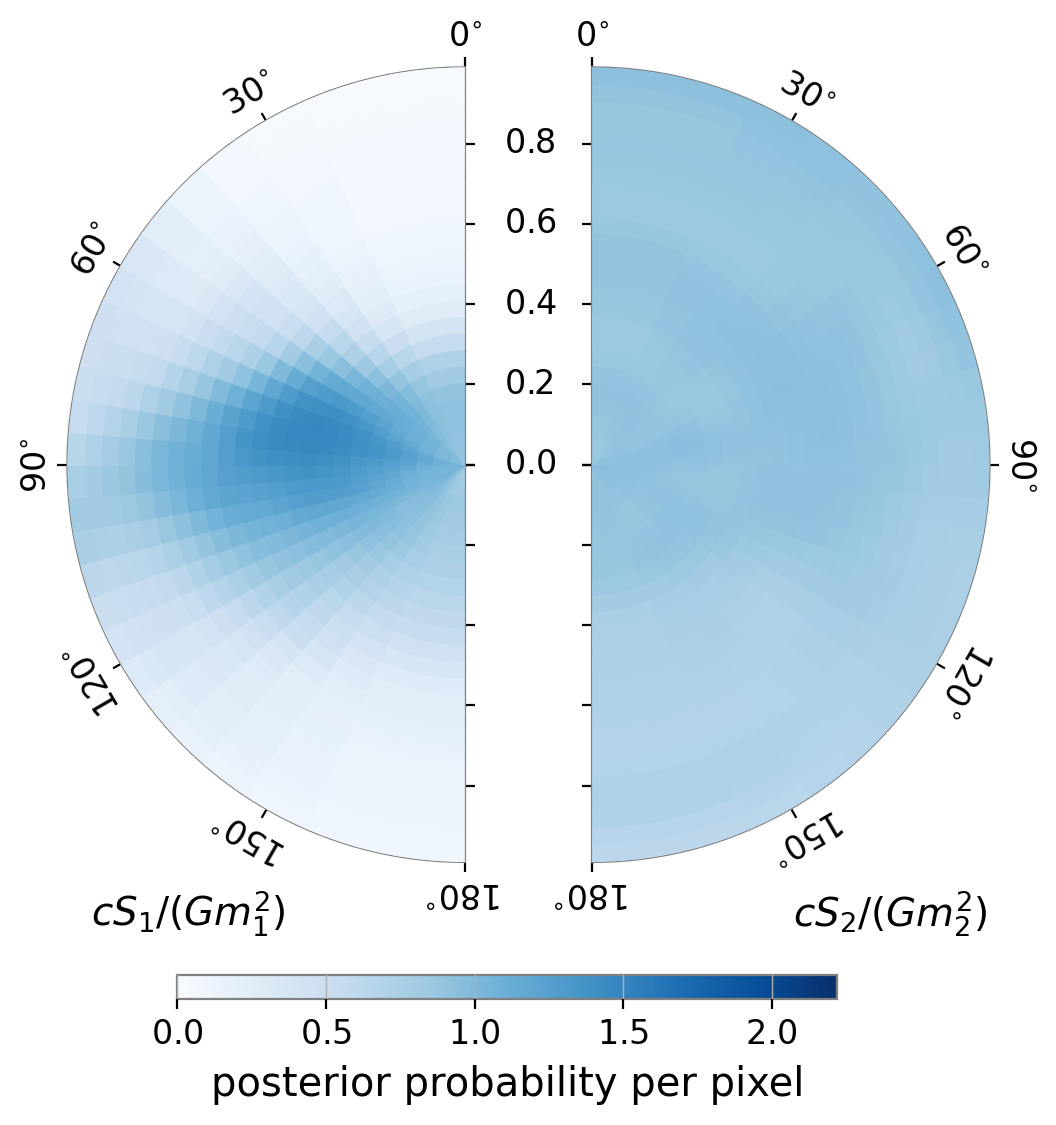

In [11]:
fig = posterior_samples.plot(type="spin_disk", colorbar=True, annotate=False,
                            show_label=True, cmap="Blues")

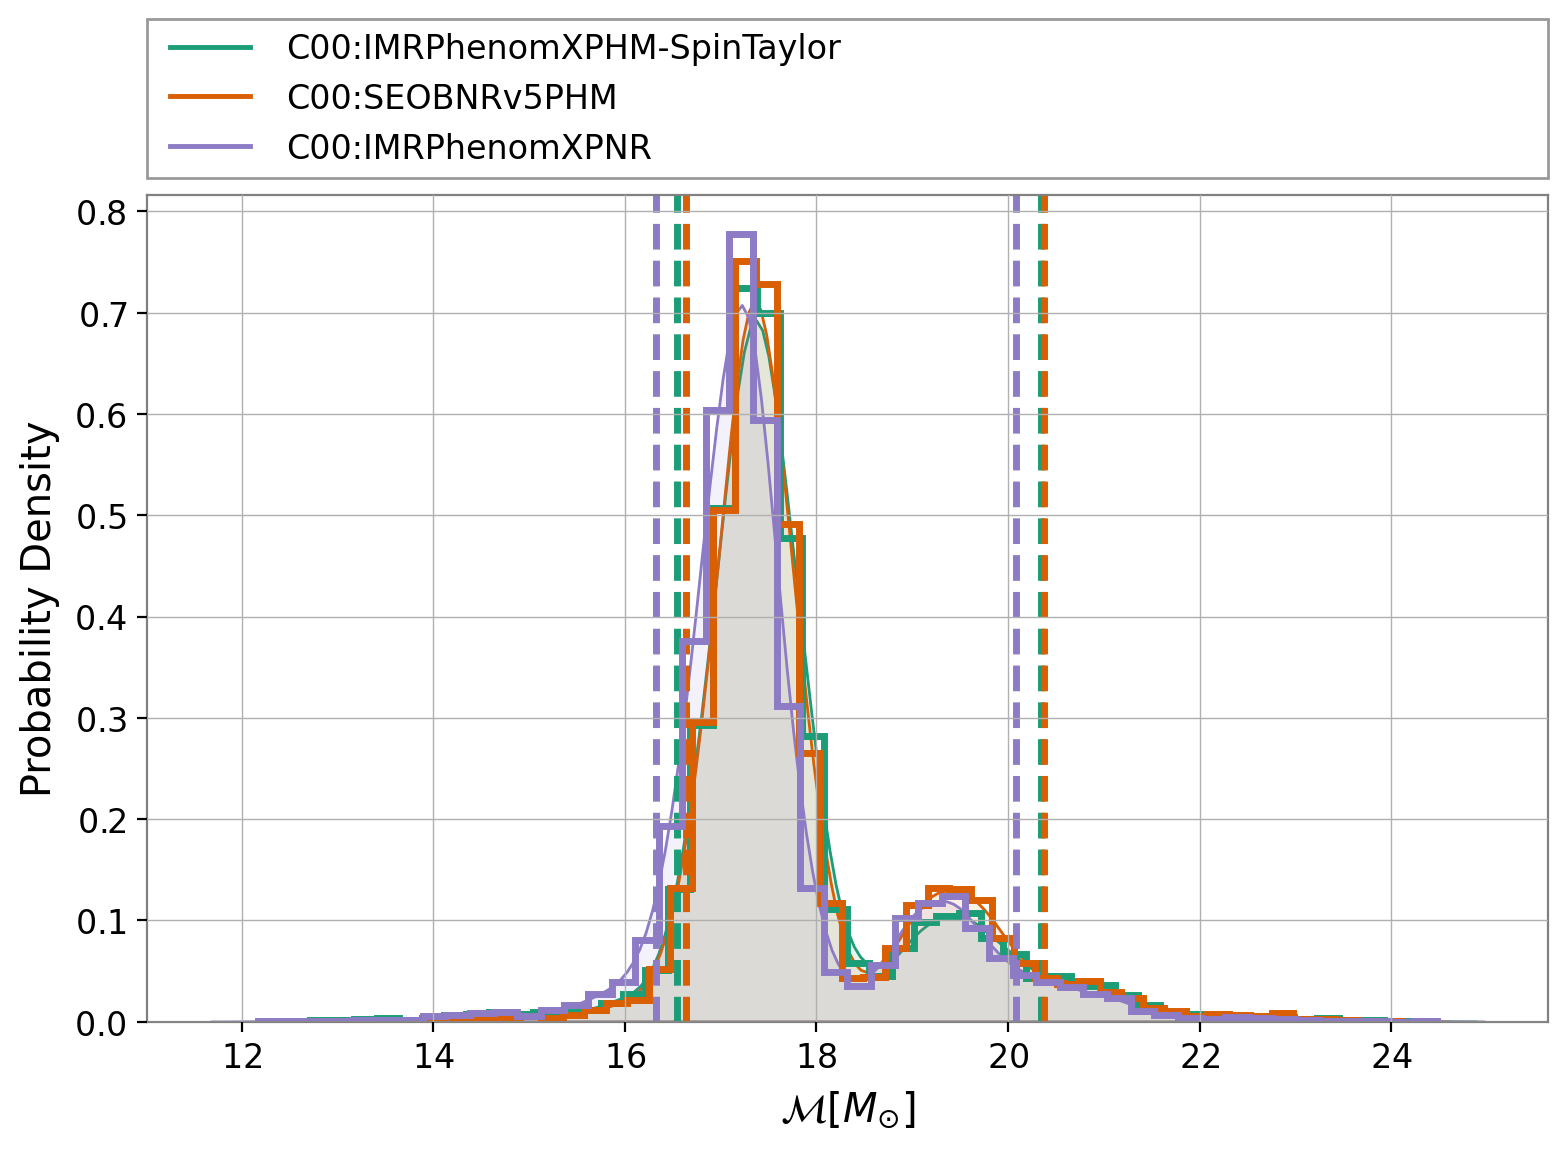

In [14]:

# select color scheme
color_palette = ["#1b9e77", "#d95f02", "#8D7BC5"]

compared_analyses = ["C00:IMRPhenomXPHM-SpinTaylor", "C00:SEOBNRv5PHM", "C00:IMRPhenomXPNR"]
fig = samples_dict.plot("chirp_mass",
                        type="hist",
                        kde=True,
                        labels=compared_analyses,
                        colors=color_palette)

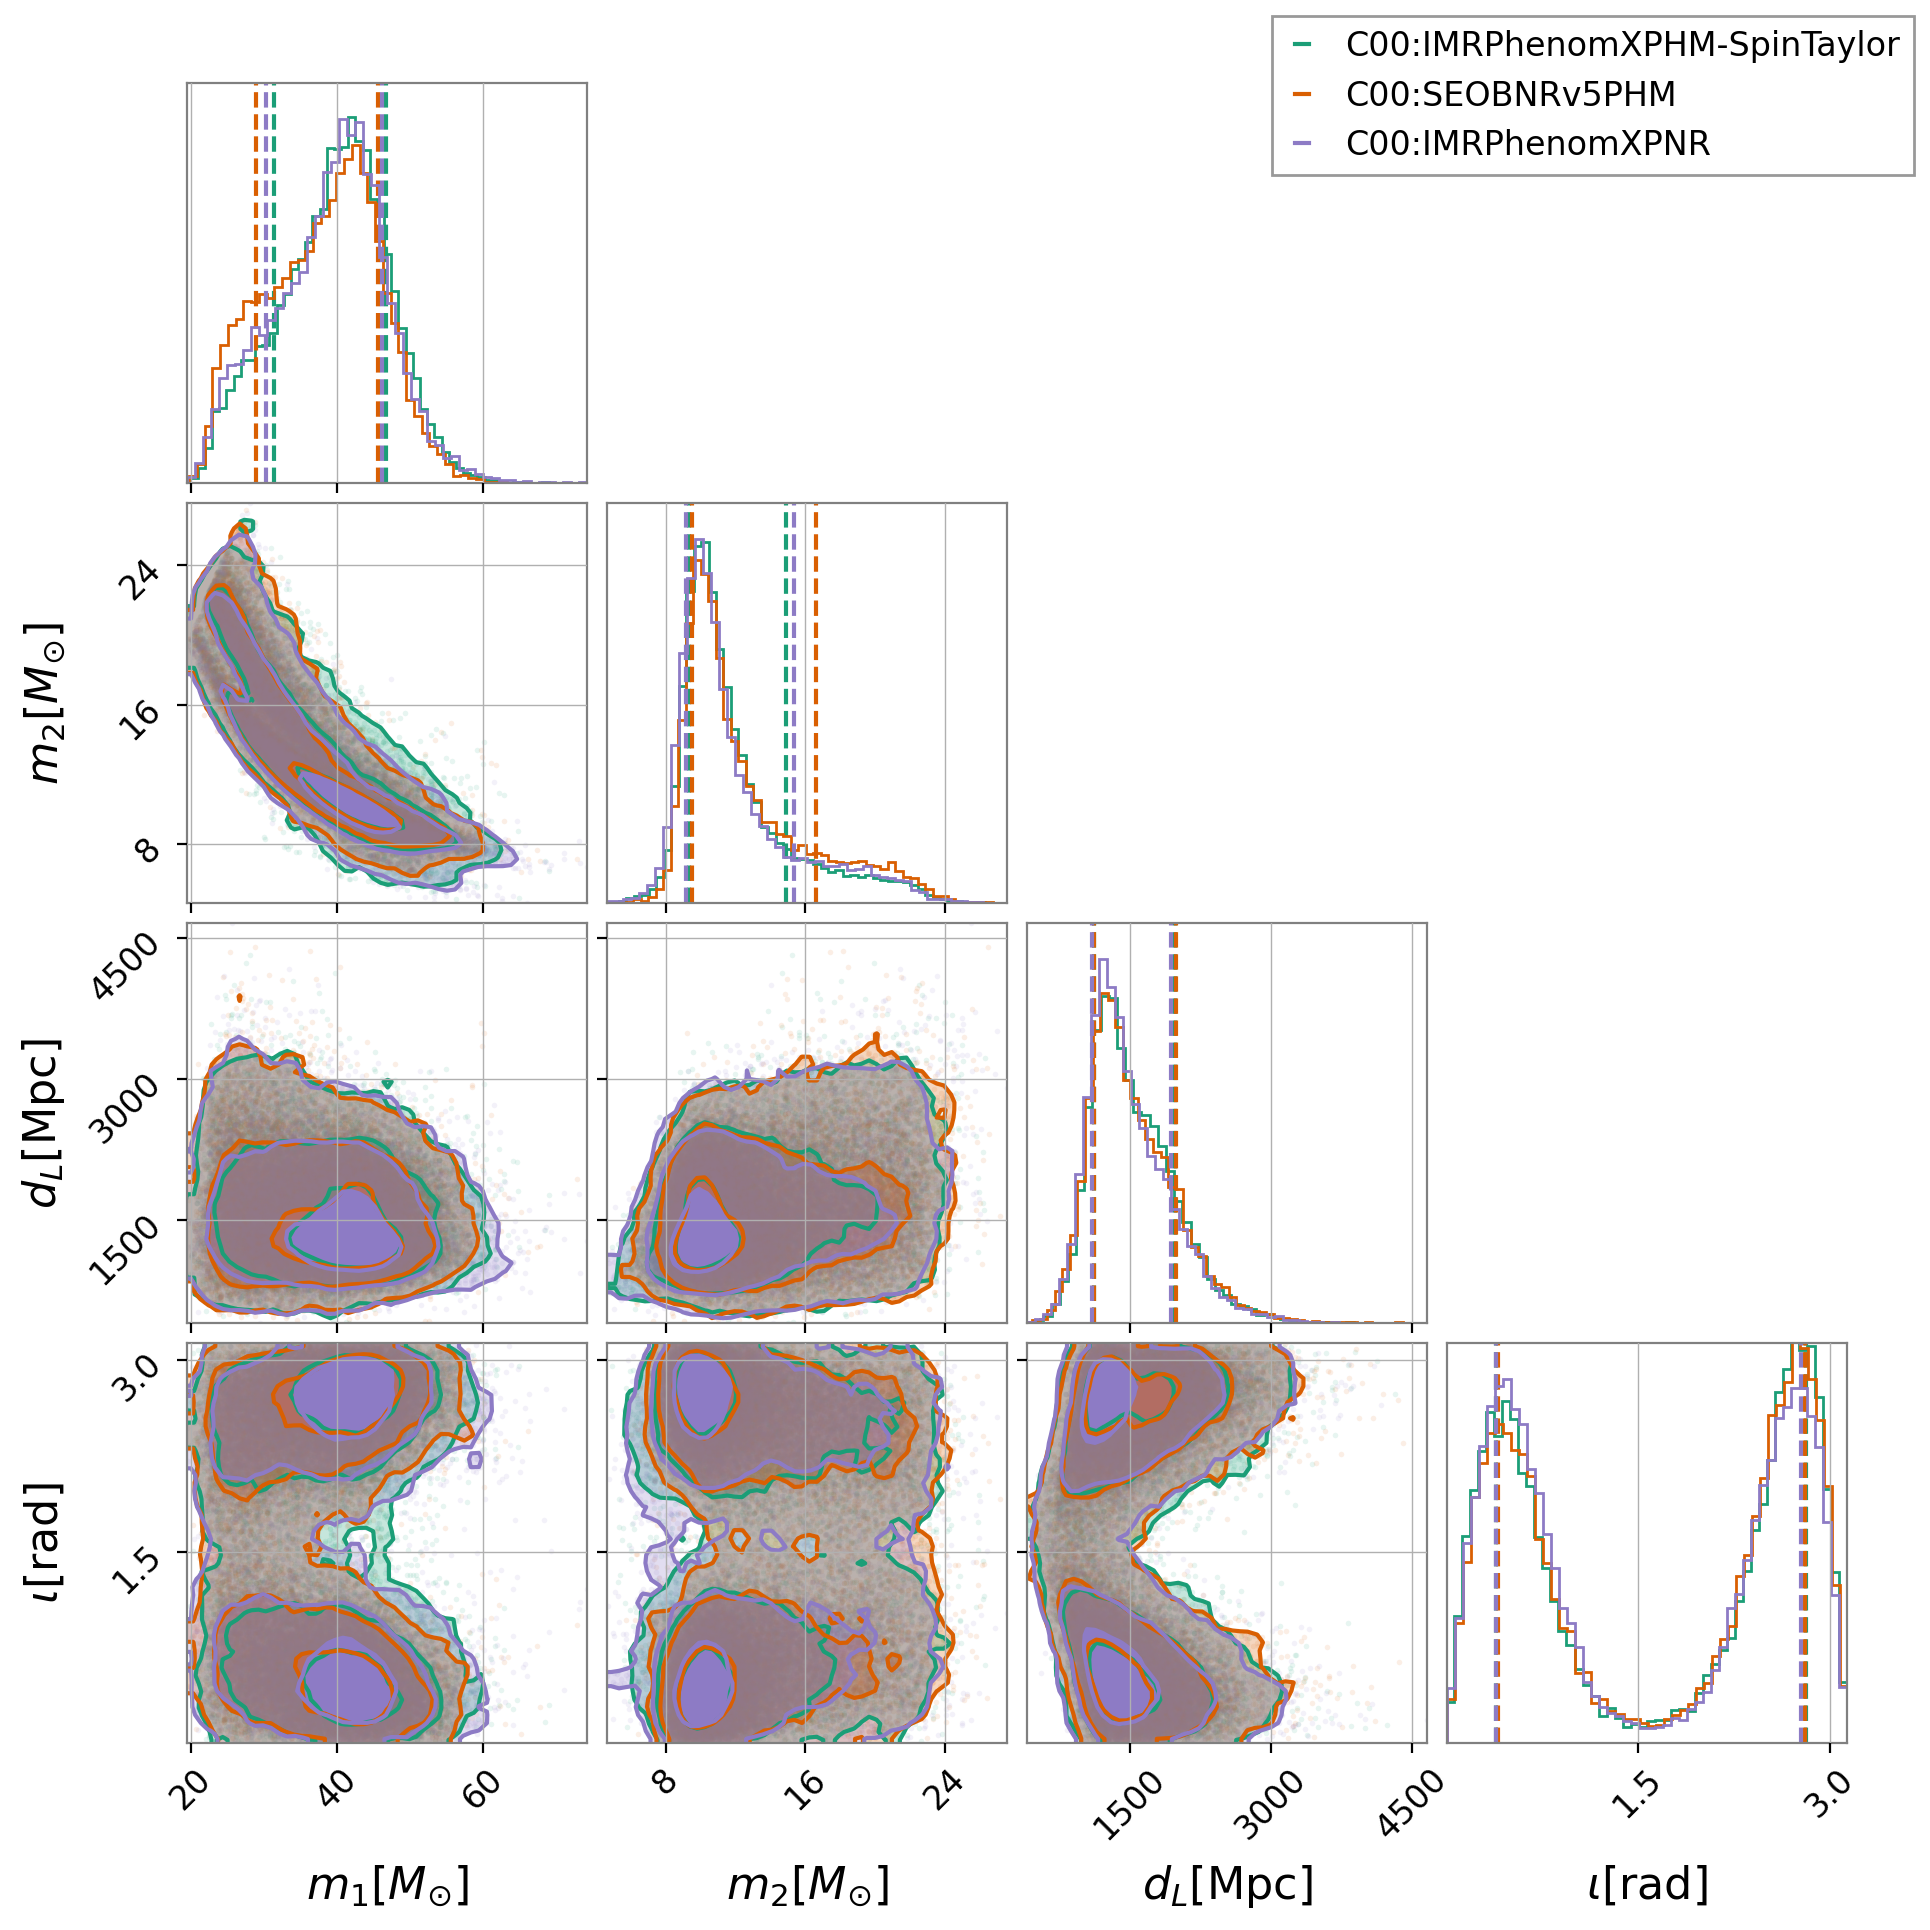

In [15]:

fig = samples_dict.plot(type="corner",
                        parameters=["mass_1",
                                    "mass_2",
                                    "luminosity_distance",
                                    "iota"],
                        labels=compared_analyses,
                        colors=color_palette)

(1e-48, 1e-40)

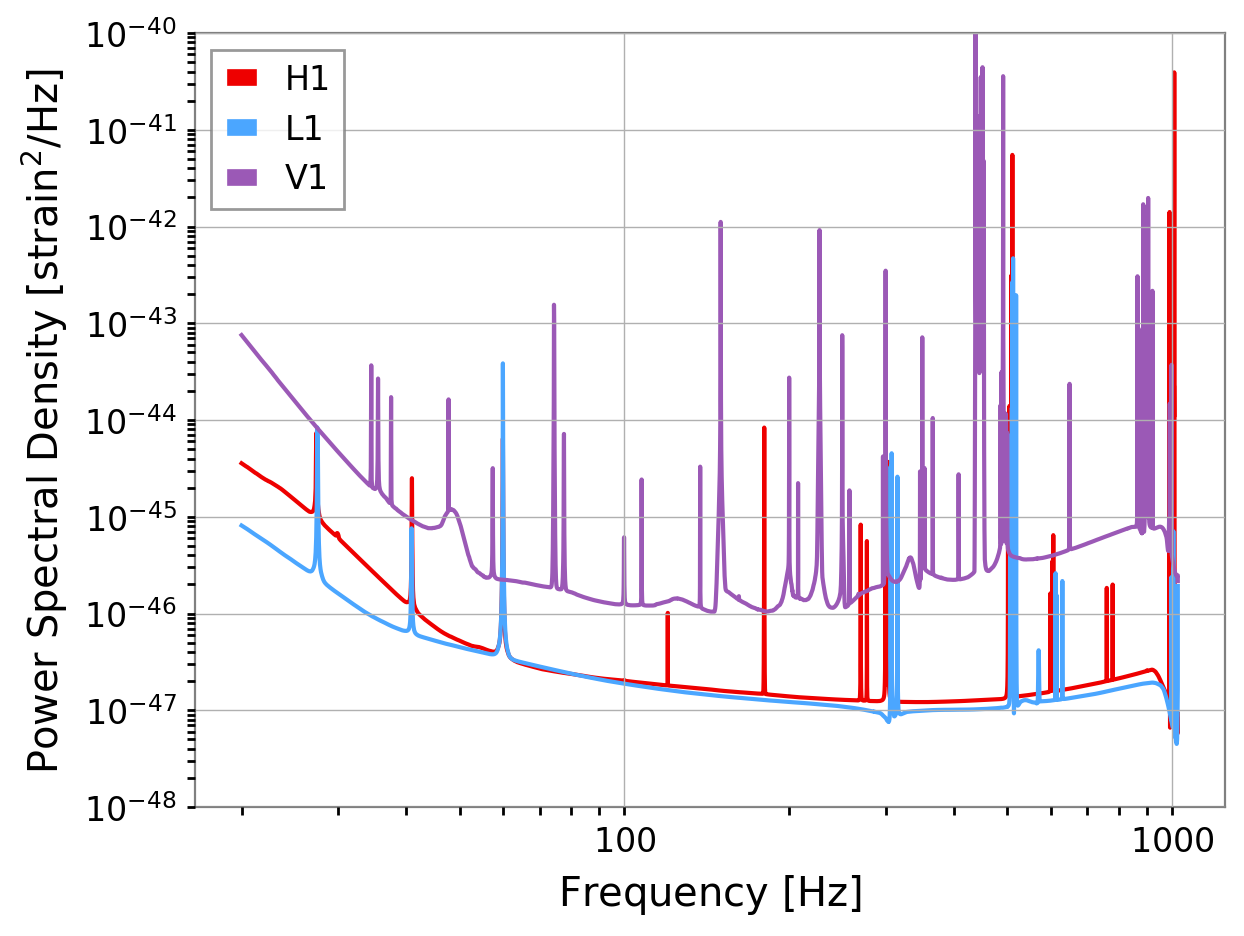

In [16]:
psd = GW240507.psd["C00:IMRPhenomXPHM-SpinTaylor"]
fig = psd.plot(fmin=20)
ax = fig.gca()
ax.set_ylim(1e-48, 1e-40)

In [17]:
approximant = "IMRPhenomXPHM"
analysis_key = "C00:IMRPhenomXPHM-SpinTaylor"
index = 100
delta_t = 1. / 4096
f_low = 10.
waveforms = samples_dict[analysis_key].td_waveform(approximant, delta_t, f_low, f_ref=f_low, ind=index)

In [18]:
waveforms = samples_dict[analysis_key].maxL_td_waveform(approximant, delta_t, f_low, f_ref=f_low)

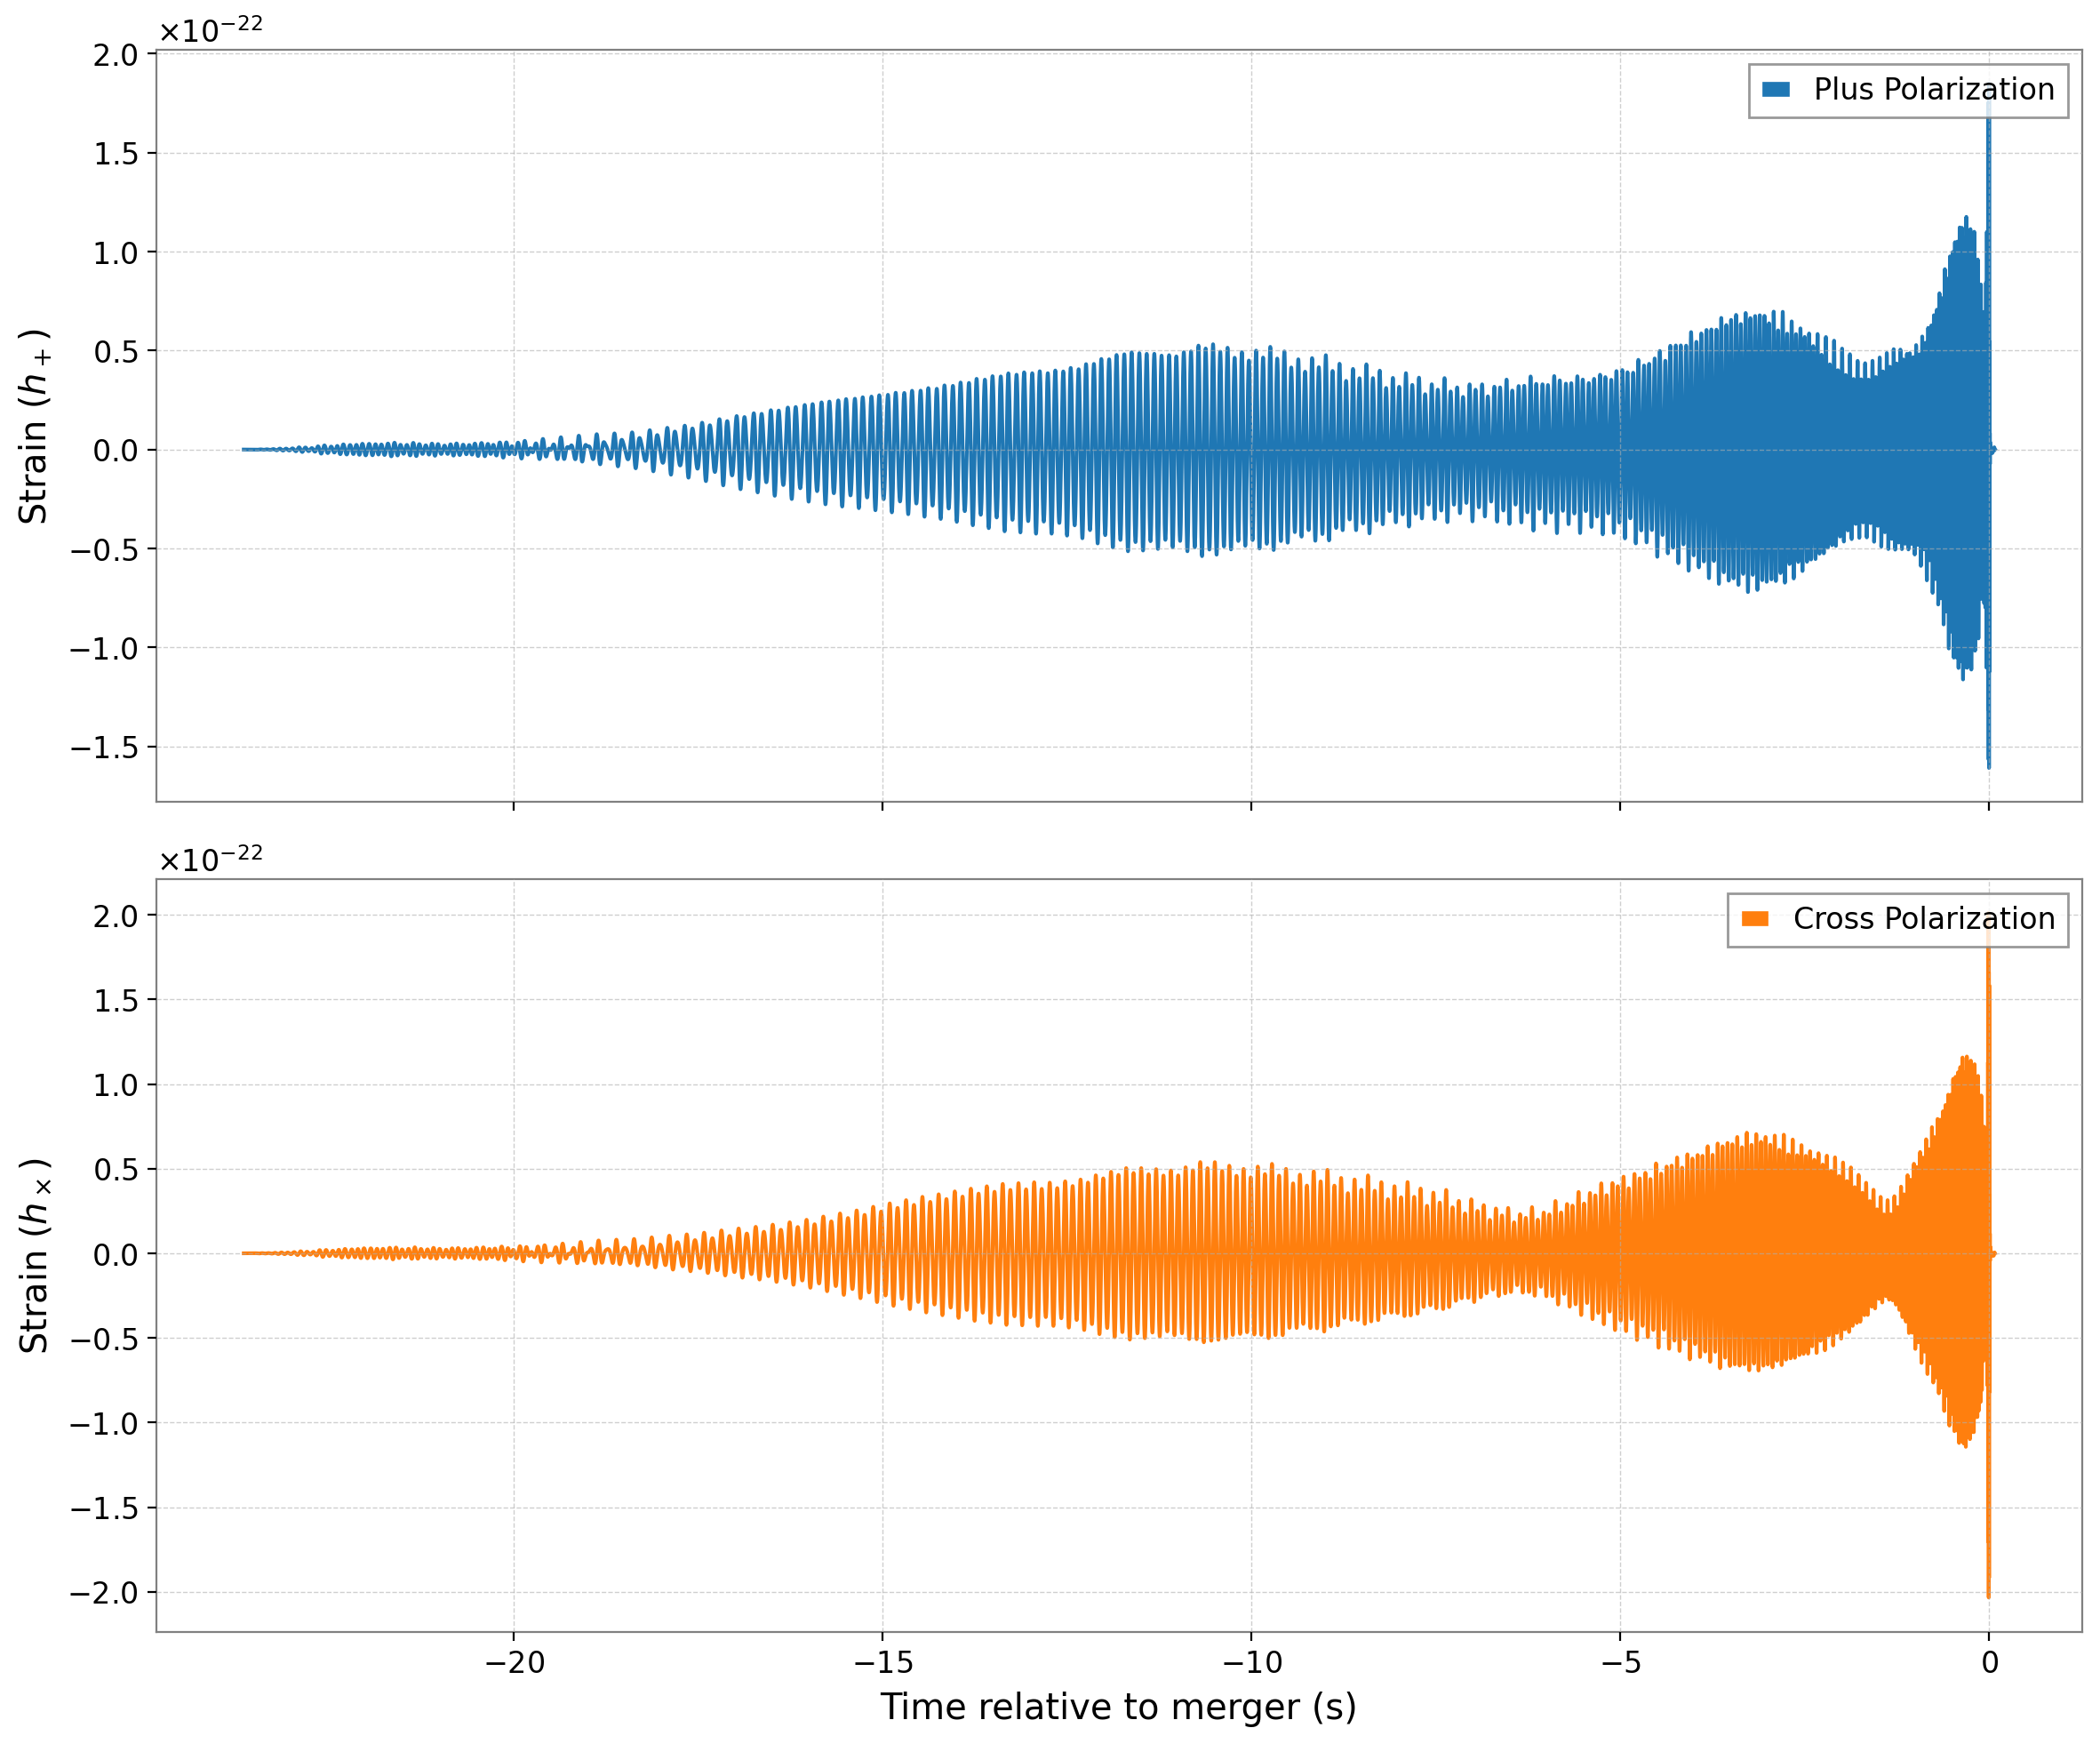

In [20]:
import matplotlib.pyplot as plt

# Create a 2x1 grid of subplots sharing the same X-axis
fig, axs = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# 1. Top Plot: Plus Polarization
axs[0].plot(waveforms["h_plus"].times, waveforms["h_plus"], label="Plus Polarization", color="tab:blue")
axs[0].set_ylabel("Strain ($h_+$)")
axs[0].legend(loc="upper right")
axs[0].grid(True, linestyle="--", alpha=0.6)

# 2. Bottom Plot: Cross Polarization
axs[1].plot(waveforms["h_cross"].times, waveforms["h_cross"], label="Cross Polarization", color="tab:orange")
axs[1].set_xlabel("Time relative to merger (s)")
axs[1].set_ylabel("Strain ($h_\\times$)")
axs[1].legend(loc="upper right")
axs[1].grid(True, linestyle="--", alpha=0.6)

# Adjust layout to prevent overlapping labels
plt.tight_layout()
plt.show()
plt.close()


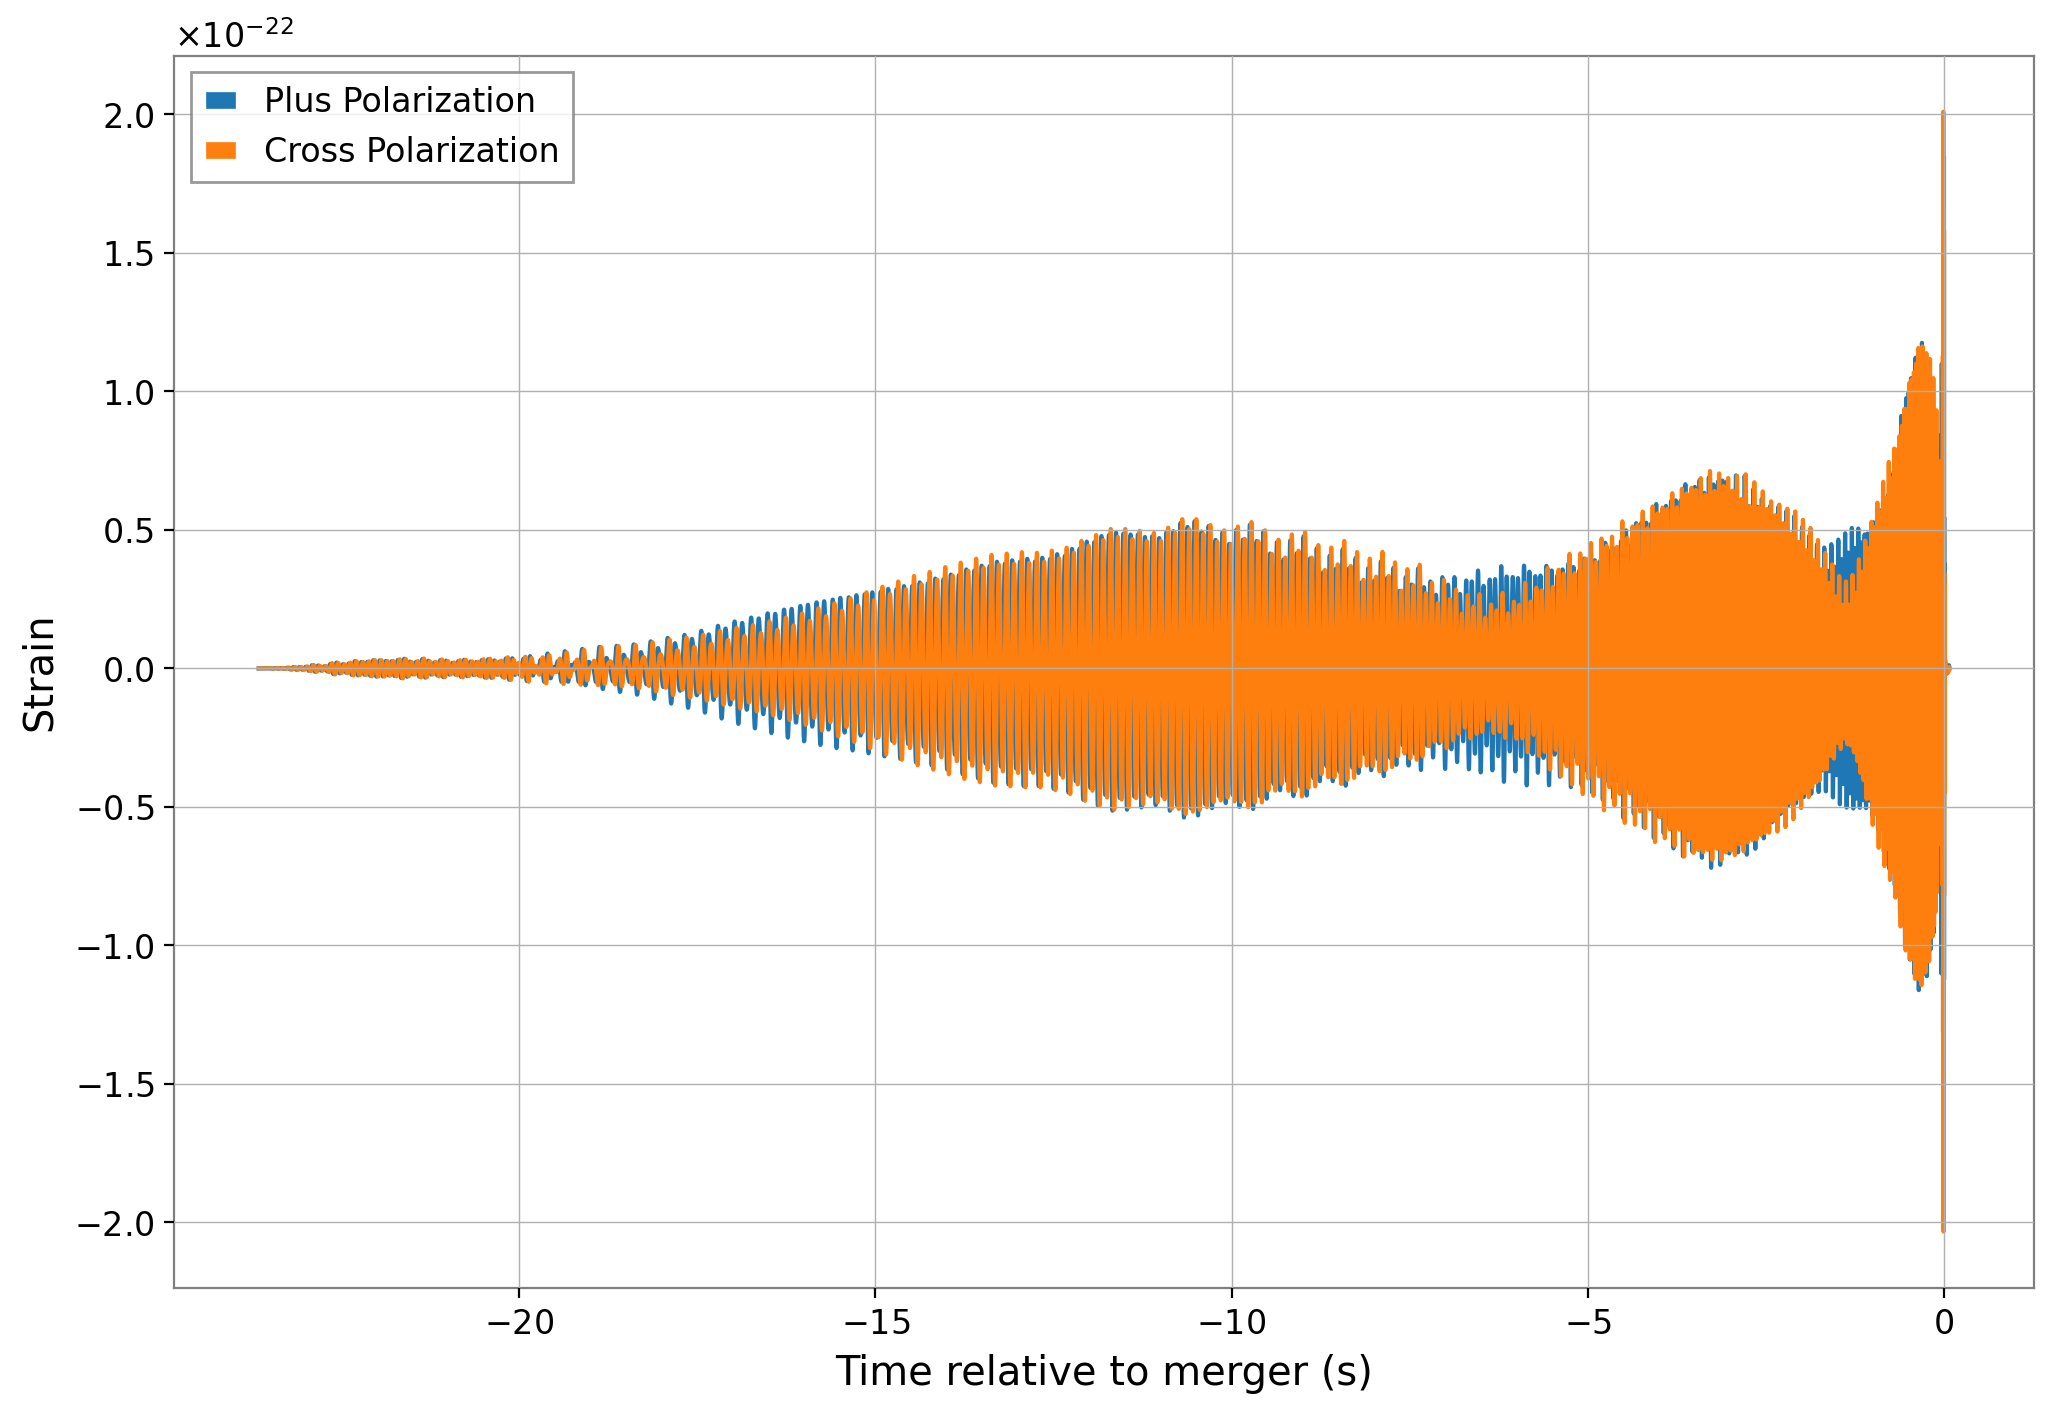

In [19]:
fig = plt.figure(figsize=(12,8))
plt.plot(waveforms["h_plus"].times, waveforms["h_plus"], label="Plus Polarization")
plt.plot(waveforms["h_cross"].times, waveforms["h_cross"], label="Cross Polarization")
plt.xlabel("Time relative to merger (s)")
plt.ylabel("Strain")
plt.legend()
plt.show()
plt.close()

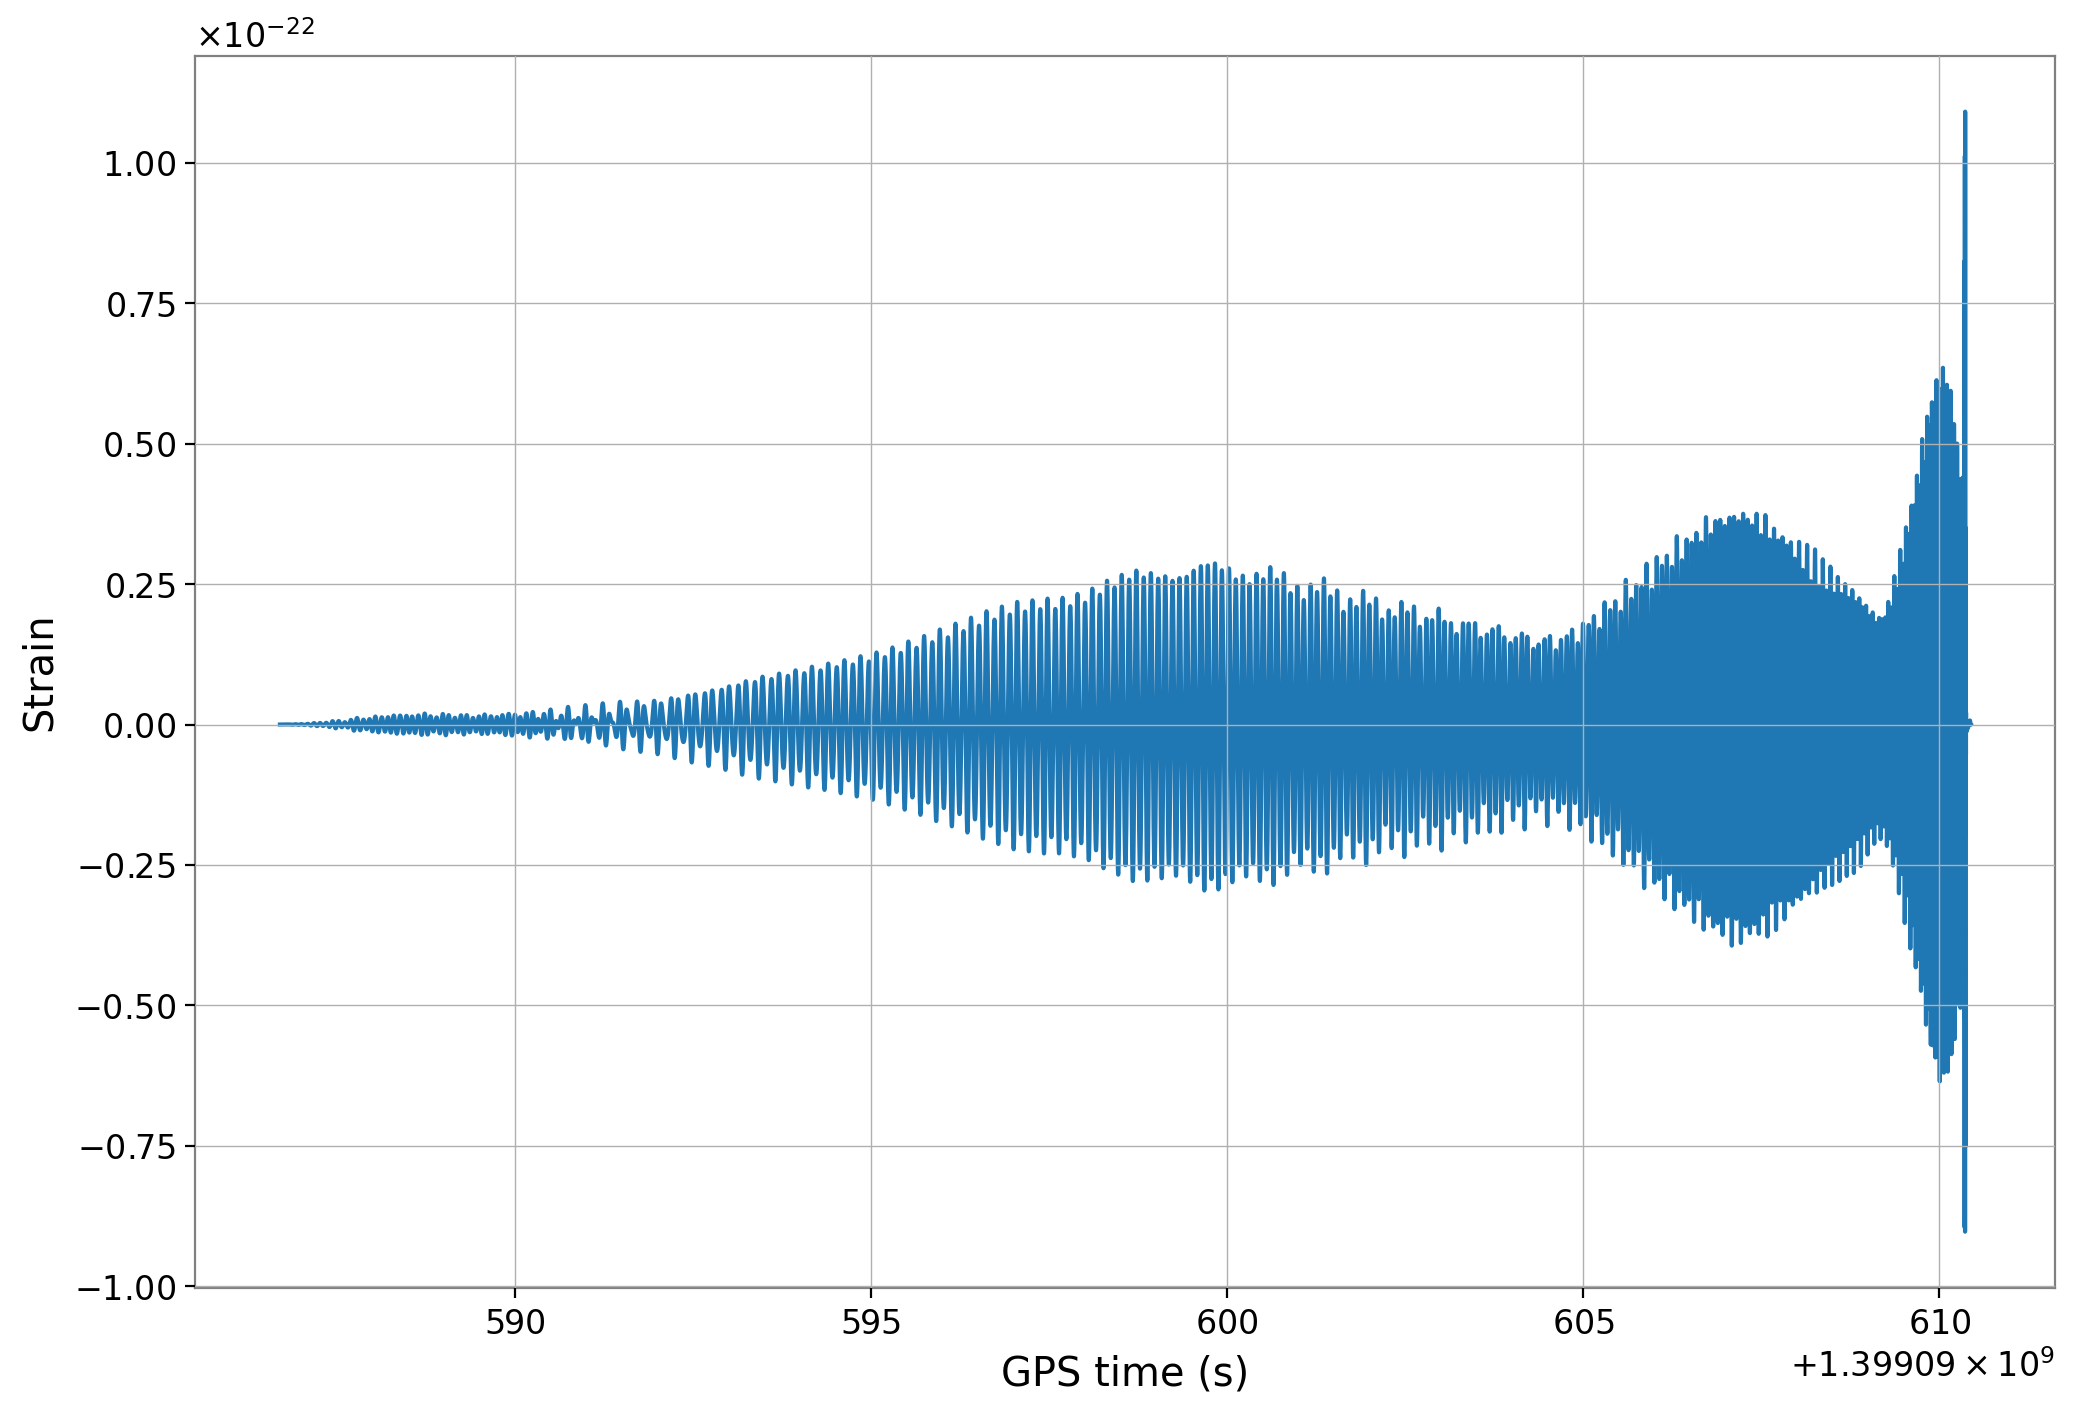

In [21]:
maxL_projected_waveform = samples_dict[analysis_key].maxL_td_waveform(approximant, delta_t, f_low, f_ref=f_low, project="L1")
fig = plt.figure(figsize=(12,8))
plt.plot(maxL_projected_waveform.times, maxL_projected_waveform)
plt.xlabel("GPS time (s)")
plt.ylabel("Strain")
plt.show()
plt.close()

In [22]:
import gwpy
merger_time = samples_dict["C00:IMRPhenomXPHM-SpinTaylor"].maxL["geocent_time"]
merger_time_UTC = gwpy.time.from_gps(merger_time).strftime("%H:%M:%S %d/%m/%Y")
print(merger_time_UTC)

04:16:32 07/05/2024
